# Does the complete OCR application read a photo correctly?

This notebook is **project evaluation**, separate from the student application.
It uses saved predictions for 16 Jy photos. **It does not train or load an OCR model.**

The assistant inspected all original photos and prepared 300 reference regions: the 298 supplied crop labels plus faint `laughing` and `gas` in Photo 14.
**The complete text and reading order still need owner confirmation. All scores below are provisional.**

Written spelling is preserved. Columns are read left to right, top to bottom within each column. Erased residue and room signage are not target text; any predicted output for them still counts against the system. Lists of unrelated words can have more than one reasonable reading order; our chosen convention is explicit, not a universal truth.

In [1]:
from pathlib import Path
import json, html, difflib, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageOps
from IPython.display import display, Markdown, HTML

cwd=Path.cwd().resolve()
PROJECT=next(p for root in [cwd,*cwd.parents] for p in [root/'whiteboard-ocr', root/'Assignment/whiteboard-ocr',root] if (p/'outputs/jy_ocr_evaluation/full_page_evaluation/answer_keys.json').is_file())
OUT=PROJECT/'outputs/jy_ocr_evaluation/full_page_evaluation'
KEYS=json.loads((OUT/'answer_keys.json').read_text())
RECALCULATE=False  # True rescoring uses saved predictions only. No GPU needed.
if RECALCULATE:
    subprocess.run([sys.executable,str(PROJECT/'scripts/evaluate_jy_full_pages.py')],check=True)
RESULT=json.loads((OUT/'evaluation.json').read_text())
summary=pd.DataFrame(RESULT['summary'])
photos=pd.read_csv(OUT/'per_photo.csv')
display(Markdown('**Status: provisional, assistant-reviewed answer keys; owner confirmation pending.**'))
display(HTML(f'<a href="{(OUT/"review.html").as_uri()}">Open all 16 photos beside their answer keys</a>'))

**Status: provisional, assistant-reviewed answer keys; owner confirmation pending.**

## 1. What are we measuring?

- **Whole-page CER:** compare all returned text, in the app's actual order, with the complete answer key. Missing words, extra text and reordered lines count. Lower is better.
- **Geometrically reordered CER:** use answer-key locations to reorder the returned regions, then score again. This is a diagnostic. **The app does not have those answer-key locations.** It retains extra output and missing targets, but is not an exact isolation of recognition errors.
- **Miss/merge/extra candidates:** inspect polygon overlaps to locate possible detector/grouping problems. These heuristic counts are not standard detector precision or recall.

All readers received the same detections/crops. S0 is the reference; S1 is the current prototype default, selected using older validation results. G0s2 is included descriptively. We do not choose a new winner on these photos.

,model,photos,targets,regions,page_CER,gt_assisted_reordered_CER,missed_targets,unmatched_predictions,merge_candidates
0,S0,16,300,301,27.92%,6.72%,0,2,1
1,S1,16,300,301,27.52%,5.64%,0,2,1
2,G0s2,16,300,301,27.62%,5.84%,0,2,1


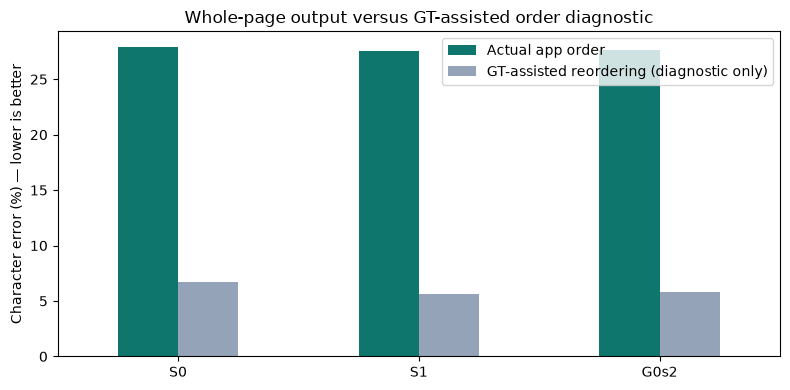

In [2]:
table=summary[['model','photos','targets','regions','page_CER','gt_assisted_reordered_CER','missed_targets','unmatched_predictions','merge_candidates']].copy()
display(table.style.format({'page_CER':'{:.2%}','gt_assisted_reordered_CER':'{:.2%}'}))
ax=summary.set_index('model')[['page_CER','gt_assisted_reordered_CER']].mul(100).plot.bar(figsize=(8,4),rot=0,color=['#0f766e','#94a3b8'])
ax.set(ylabel='Character error (%) — lower is better',xlabel='',title='Whole-page output versus GT-assisted order diagnostic')
ax.legend(['Actual app order','GT-assisted reordering (diagnostic only)'])
plt.tight_layout();plt.show()

## 2. Which photographs need attention?

A large gap between the two columns suggests inspecting layout and ordering, including whether our chosen reference order is appropriate. It does not mean the recogniser suddenly became worse at recognising individual words.

,photo_id,page_CER,gt_assisted_reordered_CER,order_gap_pp,unmatched_predictions,merge_candidates
22,15,73.6%,3.8%,69.8,0,0
19,14,72.9%,6.7%,66.2,2,0
34,19,73.8%,9.4%,64.3,0,0
1,8,74.0%,12.0%,62.0,0,1
4,9,3.0%,3.0%,0.0,0,0
7,10,4.0%,4.0%,0.0,0,0
10,11,3.2%,3.2%,0.0,0,0
13,12,5.0%,5.0%,0.0,0,0
16,13,8.1%,8.1%,0.0,0,0
25,16,8.3%,8.3%,0.0,0,0


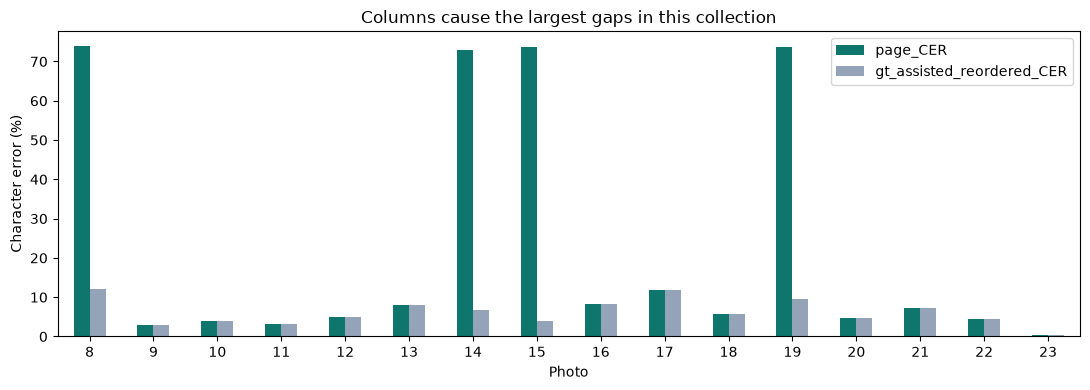

In [3]:
s1=photos[photos.model=='S1'].copy()
s1['order_gap_pp']=100*(s1.page_CER-s1.gt_assisted_reordered_CER)
display(s1[['photo_id','page_CER','gt_assisted_reordered_CER','order_gap_pp','unmatched_predictions','merge_candidates']].sort_values('order_gap_pp',ascending=False).style.format({'page_CER':'{:.1%}','gt_assisted_reordered_CER':'{:.1%}','order_gap_pp':'{:.1f}'}))
ax=s1.set_index('photo_id')[['page_CER','gt_assisted_reordered_CER']].mul(100).plot.bar(figsize=(11,4),rot=0,color=['#0f766e','#94a3b8'])
ax.set(xlabel='Photo',ylabel='Character error (%)',title='Columns cause the largest gaps in this collection')
plt.tight_layout();plt.show()

## 3. Inspect the actual photo, answer key and model output

Change `PHOTO_ID` and rerun this cell. The left image labels the reference order, while the right labels the actual detected-region order. The text comparison includes **all** app output, including extra detections. Colours in the prediction table flag text edits; they do not diagnose their cause.

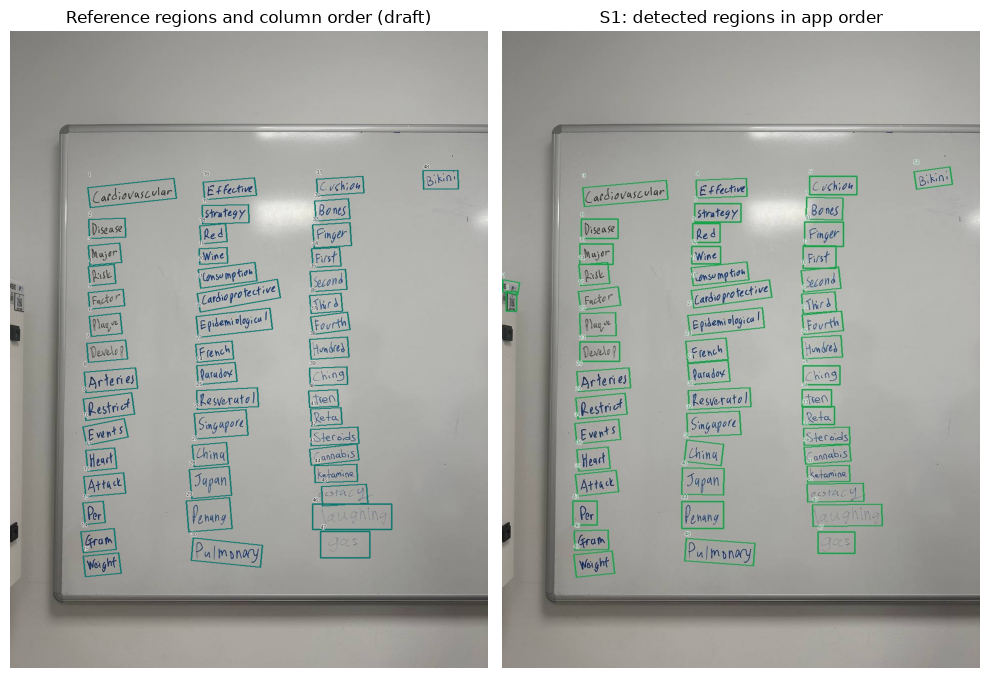

S0CER 73.5%,bela cardiovascular effective cushiou strategy bones disease red finger mucardiovascular disease major wine first arisk consumptioh second factor cardioprotective thir1 plufactor plaquve epidemiologicu 1 fourth develop french hundrel arteries parudox ching restric resverutol tren singapore reta events steroidls heart chinu cannabise develop arteries restrict events heart attack jupan ketamine ecstacy . per penany laughing gram gces pulmonaryper gram woighteight effective strategy red wine consumption cardioprotective epidemiological french paradox resveratol singapore china japan penang pulmonary cushion biones finger first second third fourth hundred ching tren reta steroids cannabis kinietamine ecstacy laughing gas bikini
S1CER 72.9%,abelr l cardiovascular effective cushion strategy bones disease red fingercardiovascular disease majon wine firstr risk consumptioh second factor cardioprotective third p)ufactor plaque epidemiologicul fourth develop french hundres arteries paradox ching restrict resverutol tren singapore reta events steroials heart ching cannabisdevelop arteries restrict events heart attack jupan ketamine ecstacy per penany laughing grum gces pulmonaryper gram woighteight effective strategy red wine consumption cardioprotective epidemiological french paradox resveratol singapore china japan penang pulmonary cushion biones finger first second third fourth hundred ching tren reta steroids cannabis kin:etamine ecstacy laughing gas bikini
G0s2CER 72.7%,abe r cardiovascular effective cushion strategy bones disease red fingercardiovascular disease major wine first risk consumptioh second factor cardioprotective third plufactor plaqve epidemiologicu l fourth develop french hundred arteries parudox ching restrict resverutol tren singapore reta events steroidls heart china cannabis a+ue develop arteries restrict events heart attack japan ketamine ecstacy per penany laughing gram gces pulmonaryper gram woighteight effective strategy red wine consumption cardioprotective epidemiological french paradox resveratol singapore china japan penang pulmonary cushion biones finger first second third fourth hundred ching tren reta steroids cannabis kinietamine ecstacy laughing gas bikini


In [4]:
PHOTO_ID=14
PHOTO_MODEL='S1'
gt=next(p for p in KEYS['photos'] if p['photo_id']==PHOTO_ID)
records=[r for r in RESULT['photos'] if r['photo_id']==PHOTO_ID]
image=ImageOps.exif_transpose(Image.open(gt['source_photo'])).convert('RGB')
canvas=image.copy();draw=ImageDraw.Draw(canvas)
for i,line in enumerate(gt['lines'],1):
    pts=[tuple(p) for p in line['quad']]
    draw.line(pts+[pts[0]],fill='#0f766e',width=3)
    draw.text((max(0,min(p[0] for p in pts)),max(0,min(p[1] for p in pts)-14)),str(i),fill='black',stroke_width=1,stroke_fill='white')
pred_image=PROJECT/f'outputs/jy_ocr_evaluation/full_photos/{PHOTO_MODEL}/Photo_{PHOTO_ID}.jpg'
fig,axes=plt.subplots(1,2,figsize=(10,7))
axes[0].imshow(canvas);axes[0].set_title('Reference regions and column order (draft)')
axes[1].imshow(Image.open(pred_image));axes[1].set_title(f'{PHOTO_MODEL}: detected regions in app order')
for ax in axes: ax.axis('off')
plt.tight_layout();plt.show()

def highlight(reference,prediction):
    a=' '.join(reference.lower().split());b=' '.join(prediction.lower().split());parts=[]
    for tag,i,j,k,l in difflib.SequenceMatcher(None,a,b).get_opcodes():
        if tag=='equal': parts.append(html.escape(b[k:l]))
        else:
            if k!=l: parts.append('<mark>'+html.escape(b[k:l])+'</mark>')
            if tag in ('delete','replace'): parts.append('<del style="color:#b91c1c">'+html.escape(a[i:j])+'</del>')
    return ''.join(parts)
rows=[]
for rec in records:
    rows.append('<tr><th>'+html.escape(rec['model'])+f"<br>CER {rec['page_CER']:.1%}</th><td>"+highlight(rec['reference'],rec['prediction'])+'</td></tr>')
display(HTML('<h4>Answer key — owner confirmation pending</h4><pre style="white-space:pre-wrap">'+html.escape(gt['reference'])+'</pre><h4>Every returned word in actual app order</h4><p>Yellow = predicted differences; red strikethrough = reference text not aligned there. Ordering differences also appear as edits.</p><table style="width:100%;text-align:left">'+''.join(rows)+'</table>'))

## 4. Missed writing, extra output and merged regions

Every target remains in scoring. Empty or missing readings count as deletions. Unmatched outputs are included in whole-page CER, unlike the earlier incomplete-label diagnostic. A merged box can still recognise both words correctly while making column ordering harder.

In [5]:
candidates=[]
for rec in RESULT['photos']:
    if rec['model']!='S1': continue
    for component in rec['components']:
        if component['kind']!='one_to_one':
            candidates.append({'photo':rec['photo_id'],'kind':component['kind'],'target IDs':', '.join(component['gt_ids']),'region numbers':str(component['prediction_indices']),'correct text':component['reference'],'prediction':component['prediction']})
display(pd.DataFrame(candidates))
display(Markdown('**Inspect these examples, not just the total score.** Photo 8 merges Membrane/Lipoproteins across columns. Photo 14 has two unmatched outputs. Geometric overlap links all 300 references, but that alone does not prove perfect detection.'))

,photo,kind,target IDs,region numbers,correct text,prediction
0,8,merge_candidate,"8.1.12, 8.2.12",[34],membrane lipoproteins,membrane lipoproteins
1,14,unmatched_prediction,,[1],,abelr
2,14,unmatched_prediction,,[2],,l


**Inspect these examples, not just the total score.** Photo 8 merges Membrane/Lipoproteins across columns. Photo 14 has two unmatched outputs. Geometric overlap links all 300 references, but that alone does not prove perfect detection.

## 5. What can we conclude and do next?

1. The current column-order convention exposes large ordering errors on Photos 8, 14, 15 and 19. Inspect those layouts before changing the recogniser.
2. S1 has lower draft page CER than S0 here, but the large ordering penalty dominates their difference. This is a single-checkpoint descriptive comparison, not a two-seed significance result.
3. Confirm all 16 answer keys, particularly the added faint words, exact spelling and column order. `review.html` shows originals and references without predictions. Source labels/photos were not changed.
4. After confirming labels, these examples can guide layout/grouping fixes. A final claim after tuning needs fresh photos. Do not call the GT-assisted ordering score the application's performance.

**This notebook and its scores belong to project evaluation. Students use the separate OCR application.**